# Smart Classroom Energy System

Synthetic-data Decision Tree demonstration. Labels follow a programmed policy, not human-verified ground truth.

In [8]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'data').exists() and (ROOT.parent / 'data').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from joblib import dump
from src.lighting_policy import FEATURES, CLASSES, lighting_policy
from src.generate_dataset import generate_dataset

In [2]:
df = pd.read_csv(ROOT / 'data/processed/classroom_training_data.csv')
df.head()

,light_level_lux,motion_detected,hour_of_day,scheduled_day,recommended_action,data_source,label_method
0,250.7,0,1,1,OFF,SYNTHETIC,Generated by the documented demonstration ligh...
1,74.7,0,13,0,OFF,SYNTHETIC,Generated by the documented demonstration ligh...
2,374.4,0,16,1,OFF,SYNTHETIC,Generated by the documented demonstration ligh...
3,444.3,0,13,1,OFF,SYNTHETIC,Generated by the documented demonstration ligh...
4,32.9,1,23,1,OFF,SYNTHETIC,Generated by the documented demonstration ligh...


In [3]:
print('Shape:', df.shape)
print('Missing values:\n', df.isna().sum())
print('Duplicate feature rows:', df.duplicated(subset=FEATURES).sum())
print(df['recommended_action'].value_counts())
assert df['light_level_lux'].ge(0).all()
assert df['hour_of_day'].between(0,23).all()
assert df['motion_detected'].isin([0,1]).all()
assert df['scheduled_day'].isin([0,1]).all()
assert set(df['recommended_action']) == {'OFF','ON'}

Shape: (2501, 7)
Missing values:
 light_level_lux       0
motion_detected       0
hour_of_day           0
scheduled_day         0
recommended_action    0
data_source           0
label_method          0
dtype: int64
Duplicate feature rows: 0
recommended_action
OFF    2146
ON      355
Name: count, dtype: int64


## Explore data

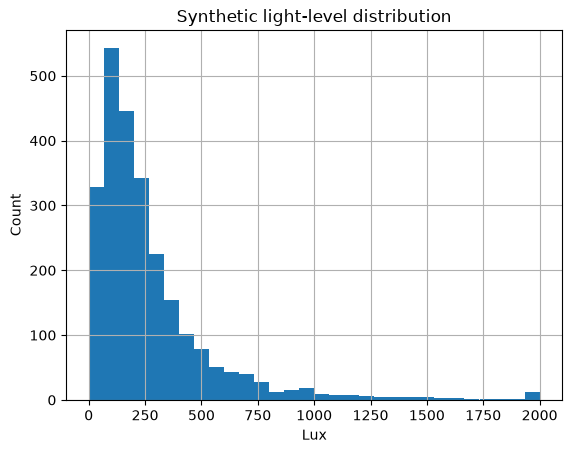

,count,mean,std,min,25%,50%,75%,max
recommended_action,,,,,,,,
OFF,2146.0,289.730429,301.044023,12.1,103.75,197.05,358.375,2000.0
ON,355.0,170.459437,99.053065,0.0,90.30,155.80,247.800,399.9


In [4]:
df['light_level_lux'].hist(bins=30)
plt.title('Synthetic light-level distribution')
plt.xlabel('Lux'); plt.ylabel('Count'); plt.show()
df.groupby('recommended_action')['light_level_lux'].describe()

## Split, train and evaluate

In [5]:
X, y = df[FEATURES], df['recommended_action']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model = DecisionTreeClassifier(max_depth=6, min_samples_leaf=5, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)
print('Accuracy:', accuracy_score(y_test, pred))
print(classification_report(y_test, pred, labels=CLASSES, zero_division=0))
print('Confusion matrix (OFF, ON):\n', confusion_matrix(y_test, pred, labels=CLASSES))

Accuracy: 1.0
              precision    recall  f1-score   support

         OFF       1.00      1.00      1.00       430
          ON       1.00      1.00      1.00        71

    accuracy                           1.00       501
   macro avg       1.00      1.00      1.00       501
weighted avg       1.00      1.00      1.00       501

Confusion matrix (OFF, ON):
 [[430   0]
 [  0  71]]


## Compare with transparent policy baseline

In [6]:
baseline = [lighting_policy(r.light_level_lux, int(r.motion_detected), int(r.hour_of_day), int(r.scheduled_day)) for r in X_test.itertuples(index=False)]
print('Baseline agreement:', (pred == baseline).mean())

Baseline agreement: 1.0


## Save model and example prediction

In [7]:
dump(model, ROOT / 'models/decision_tree.joblib')
example = pd.DataFrame([[180,1,10,1]], columns=FEATURES)
print('Example prediction:', model.predict(example)[0])

Example prediction: ON
